# 02 – Clean the sample

The sample (1M random sessions) is made by `src/make_sample.py`. It only needs to run once, either from the terminal:

```
python src/make_sample.py
```

or from here, with the cell below. Skip that cell if `events_sample_raw.parquet` already exists.

Here the sample is checked and cleaned, then saved for PostgreSQL.

In [ ]:
#%pip install pyarrow

In [1]:
# only needed once, takes a few minutes
%run ../src/make_sample.py

1,000,000 lines read
2,000,000 lines read
3,000,000 lines read
4,000,000 lines read
5,000,000 lines read
6,000,000 lines read
7,000,000 lines read
8,000,000 lines read
9,000,000 lines read
10,000,000 lines read
11,000,000 lines read
12,000,000 lines read
Saved 1,000,000 sessions and 16,883,743 events to F:\DataAnalytics\capstone-project\otto-cart-recovery\data\processed\events_sample_raw.parquet


In [2]:
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

DATA_DIR = Path("../data/processed")

In [3]:
events = pd.read_parquet(DATA_DIR / "events_sample_raw.parquet")
print(events.shape)
print(events.dtypes)
events.head()

(16883743, 4)
session       int32
aid           int32
ts            int64
type       category
dtype: object


,session,aid,ts,type
0,1,424964,1659304800025,carts
1,1,1492293,1659304852871,clicks
2,1,1492293,1659304863627,carts
3,1,910862,1659304891923,clicks
4,1,910862,1659304900209,carts


## 1. Readable time

`ts` is Unix time in milliseconds. OTTO is a German shop, so it's converted to Berlin time.

In [4]:
events["event_time"] = pd.to_datetime(events["ts"], unit="ms", utc=True).dt.tz_convert("Europe/Berlin")
events[["ts", "event_time"]].head()

,ts,event_time
0,1659304800025,2022-08-01 00:00:00.025000+02:00
1,1659304852871,2022-08-01 00:00:52.871000+02:00
2,1659304863627,2022-08-01 00:01:03.627000+02:00
3,1659304891923,2022-08-01 00:01:31.923000+02:00
4,1659304900209,2022-08-01 00:01:40.209000+02:00


## 2. Checks

In [5]:
# missing values
events.isna().sum()

session       0
aid           0
ts            0
type          0
event_time    0
dtype: int64

In [6]:
print("Sessions:", events["session"].nunique())
print("From:", events["event_time"].min())
print("To:  ", events["event_time"].max())

Sessions: 1000000
From: 2022-08-01 00:00:00.025000+02:00
To:   2022-08-28 23:59:59.069000+02:00


Is the sample similar to the full data? Compare the share of each event type with the totals from notebook 01.

In [7]:
population = pd.read_csv(DATA_DIR / "population_summary.csv")

sample_share = (events["type"].value_counts(normalize=True) * 100).round(2)
compare = population[["event_type", "share_of_events_%"]].rename(columns={"share_of_events_%": "full_data_%"})
compare["sample_%"] = compare["event_type"].map(sample_share)
compare

,event_type,full_data_%,sample_%
0,clicks,89.85,89.84
1,carts,7.80,7.80
2,orders,2.35,2.36


### Duplicates

A duplicate here means same session, same product, same type and the exact same millisecond.

In [8]:
dups = events.duplicated(subset=["session", "aid", "ts", "type"])
print(f"Duplicate rows: {dups.sum():,} ({dups.mean() * 100:.2f}%)")
events[dups]["type"].value_counts()

Duplicate rows: 26,197 (0.16%)


type
orders    17867
clicks     7679
carts       651
Name: count, dtype: int64

Most duplicates are orders. There's no quantity column, so we can't tell if it's a double log or the same product bought twice.
They're less than 1% of rows, so they're dropped: one row per product per event.

### Sessions that start with a cart or an order

These users added the product before the data period started (end of July), so the click is missing.
They stay in the data, but they'll be left out when we measure the time from cart to order.

In [9]:
first_type = events.sort_values(["session", "ts"]).groupby("session")["type"].first()
first_type.value_counts(normalize=True).mul(100).round(2)

type
clicks    99.57
carts      0.29
orders     0.14
Name: proportion, dtype: float64

## 3. Clean and save

In [10]:
before = len(events)
events_clean = events.drop_duplicates(subset=["session", "aid", "ts", "type"]).reset_index(drop=True)
print(f"Rows before: {before:,}")
print(f"Rows after:  {len(events_clean):,}")
print(f"Removed:     {before - len(events_clean):,}")

Rows before: 16,883,743
Rows after:  16,857,546
Removed:     26,197


In [11]:
events_clean.to_parquet(DATA_DIR / "events_clean.parquet", index=False)

## 4. Charts

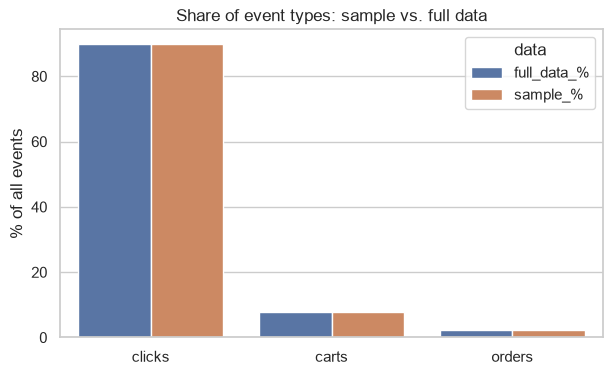

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_data = compare.melt(id_vars="event_type", var_name="data", value_name="share_%")
sns.barplot(data=plot_data, x="event_type", y="share_%", hue="data", ax=ax)
ax.set_title("Share of event types: sample vs. full data")
ax.set_xlabel("")
ax.set_ylabel("% of all events")
plt.show()

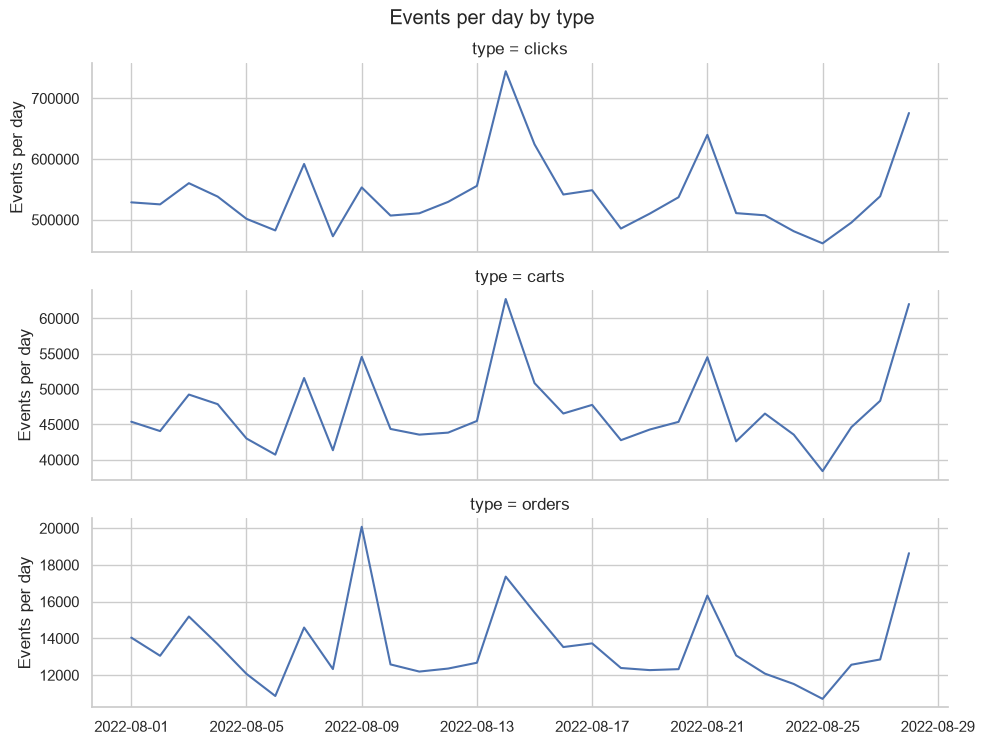

In [13]:
daily = (
    events_clean
    .assign(date=events_clean["event_time"].dt.date)
    .groupby(["date", "type"], observed=True)
    .size()
    .reset_index(name="events")
)

g = sns.relplot(data=daily, x="date", y="events", row="type", kind="line",
                height=2.5, aspect=4, facet_kws={"sharey": False})
g.set_axis_labels("", "Events per day")
g.figure.suptitle("Events per day by type", y=1.02)
plt.show()